# Comparison of PhosphoPCA Screening to In Vitro (Kinexus) Validation

This notebook compares barcoded PhosphoPCA yeast screening hits against in vitro
biochemical validation data from the Kinexus peptide array platform.

---
### Table of Contents
1. [Setup & Imports](#1-setup--imports)
2. [Load & Process Kinexus Raw Data](#2-load--process-kinexus-raw-data)
3. [Replicate QC — Filter Inconsistent Replicates](#3-replicate-qc--filter-inconsistent-replicates)
4. [Call In Vitro Positives](#4-call-in-vitro-positives)
5. [Merge with PhosphoPCA Screening Hits](#5-merge-with-phosphopca-screening-hits)
6. [Overlap Analysis & Venn Diagram](#6-overlap-analysis--venn-diagram)
7. [Summary](#7-summary)

---
## 1. Setup & Imports

In [80]:
import subprocess
subprocess.run(['pip', 'install', 'openpyxl', 'matplotlib-venn', '--quiet'], check=True)

CompletedProcess(args=['pip', 'install', 'openpyxl', 'matplotlib-venn', '--quiet'], returncode=0)

In [81]:
common_name_mapping = pd.DataFrame({
    'uniprot_acc': [
        'KS6B1_HUMAN_wt', 'PLK1_HUMAN', 'TBK1_HUMAN', 'PDPK1_HUMAN',
        'IKKB_HUMAN', 'FYN_HUMAN', 'FES_HUMAN', 'KSYK_HUMAN', 'FRK_HUMAN', 'DYRK4_HUMAN'
    ],
    'common_name': [
        'P70S6K', 'PLK1', 'TBK1', 'PDK1',
        'IKKB', 'FYN', 'FES', 'SYK', 'FRK', 'DYRK4'
    ],
})

In [82]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import matplotlib.cm as mplcm
import seaborn as sns
from matplotlib_venn import venn2
from plotnine import *
from scipy import stats
import statsmodels.api as sm

%matplotlib inline

# ── Summer palette (consistent with notebook 8) ───────────────────────────────
_summer = mplcm.get_cmap('summer')
SUMMER = {
    'deep':   _summer(0.10),   # deep green  — PhosphoPCA only / primary
    'mid':    _summer(0.45),   # mid-green   — overlap
    'light':  _summer(0.80),   # yellow-green — in vitro only
    'pale':   _summer(0.95),   # near-yellow  — background
}

plt.rcParams.update({
    'font.family':    'sans-serif',
    'font.size':      11,
    'axes.linewidth': 0.8,
    'savefig.dpi':    300,
    'savefig.bbox':   'tight',
})

print('Imports complete.')

Imports complete.


In [83]:
# Copy input files from upstream analysis directory (run once)
import shutil, os
for src in [
    '../dms_analysis/single_yeast_measurements/kinexus_results.xlsx',
    '../dms_analysis/single_yeast_measurements/validation_substrate_candidate_information.csv',
]:
    dst = os.path.basename(src)
    if not os.path.exists(dst):
        shutil.copy(src, dst)
        print(f'Copied {dst}')
    else:
        print(f'Already present: {dst}')

Already present: kinexus_results.xlsx
Already present: validation_substrate_candidate_information.csv


---
## 2. Load & Process Kinexus Raw Data

The Kinexus array is split across two sheets and two plate halves per sheet.
Processing steps for each half:
1. Subtract the last column (non-specific background) row-wise.
2. Subtract the mean signal of empty-peptide wells column-wise.
3. Melt to long format and attach substrate labels.

In [84]:
def process_raw(df):
    """
    Background-correct a Kinexus plate half.

    Steps
    -----
    1. Rename columns: first two become 'Sequence' and 'Pos'; remainder
       are labelled by the last whitespace-delimited token (kinase name).
    2. Subtract the last column (NS control) row-wise from all data columns.
    3. Subtract per-kinase mean of empty-peptide wells from all data rows.
    4. Drop control rows; return data columns only.
    """
    df = df.copy()
    df.columns = ['Sequence', 'Pos'] + [c.split(' ')[-1] for c in df.columns[2:]]

    # 1. Row-wise background subtraction (last col = NS control)
    df.iloc[:, 2:-1] = df.iloc[:, 2:-1].sub(df.iloc[:, -1], axis=0)

    # 2. Column-wise empty-well subtraction
    mean_empty = df.loc[df['Sequence'] == 'empty', :].iloc[:, 2:-1].mean(axis=0)
    df.iloc[:-2, 2:-1] = df.iloc[:-2, 2:-1].sub(mean_empty, axis=1)

    return df.iloc[:-2, 2:-1]  # drop last 2 control rows, return data columns


def load_kinexus_sheet(sheet_name, n_rows_part1=112):
    """
    Load one Kinexus Excel sheet, process both plate halves, and return
    a long-format DataFrame with columns: kinase, value1, value2, substrate.
    """
    raw = pd.read_excel('./kinexus_results.xlsx', sheet_name=sheet_name)
    part1_raw = raw.iloc[:n_rows_part1, :]
    part2_raw = raw.iloc[n_rows_part1:, :]

    df1 = process_raw(part1_raw).melt()
    df2 = process_raw(part2_raw).melt()

    # number of kinase columns differs between sheets — infer from shape
    n_kinases = process_raw(part1_raw).shape[1]
    substrate_labels = pd.concat(
        [part1_raw['Sequence'].iloc[:-2]] * n_kinases
    ).tolist()

    combined = pd.concat([df1, df2], axis=1)
    combined.columns = ['kinase', 'value1', 'kinase2', 'value2']
    combined['substrate'] = substrate_labels
    return combined.drop('kinase2', axis=1)


df_pt1 = load_kinexus_sheet('raw_data_1', n_rows_part1=112)
df_pt2 = load_kinexus_sheet('raw_data_2', n_rows_part1=112)
df_all = pd.concat([df_pt1, df_pt2], ignore_index=True)

print(f'Loaded {df_all.shape[0]:,} kinase–substrate measurements across both plates.')
df_all.head()

Loaded 1,210 kinase–substrate measurements across both plates.


,kinase,value1,value2,substrate
0,IKKB,2288.2372,3198.3967,CPRLRIFSHPNVLPV
1,IKKB,591.6190,-417.0372,WKNIDDASQMDLFHR
2,IKKB,527.6292,-16.5790,PLLSRMGSLRAPVDE
3,IKKB,446.1061,-158.3729,LESTIFGSPRLASGL
4,IKKB,3450.2104,4261.5801,KVVRPLRTFLHTVQR


### 2a. Distribution of replicate 1 signal by kinase

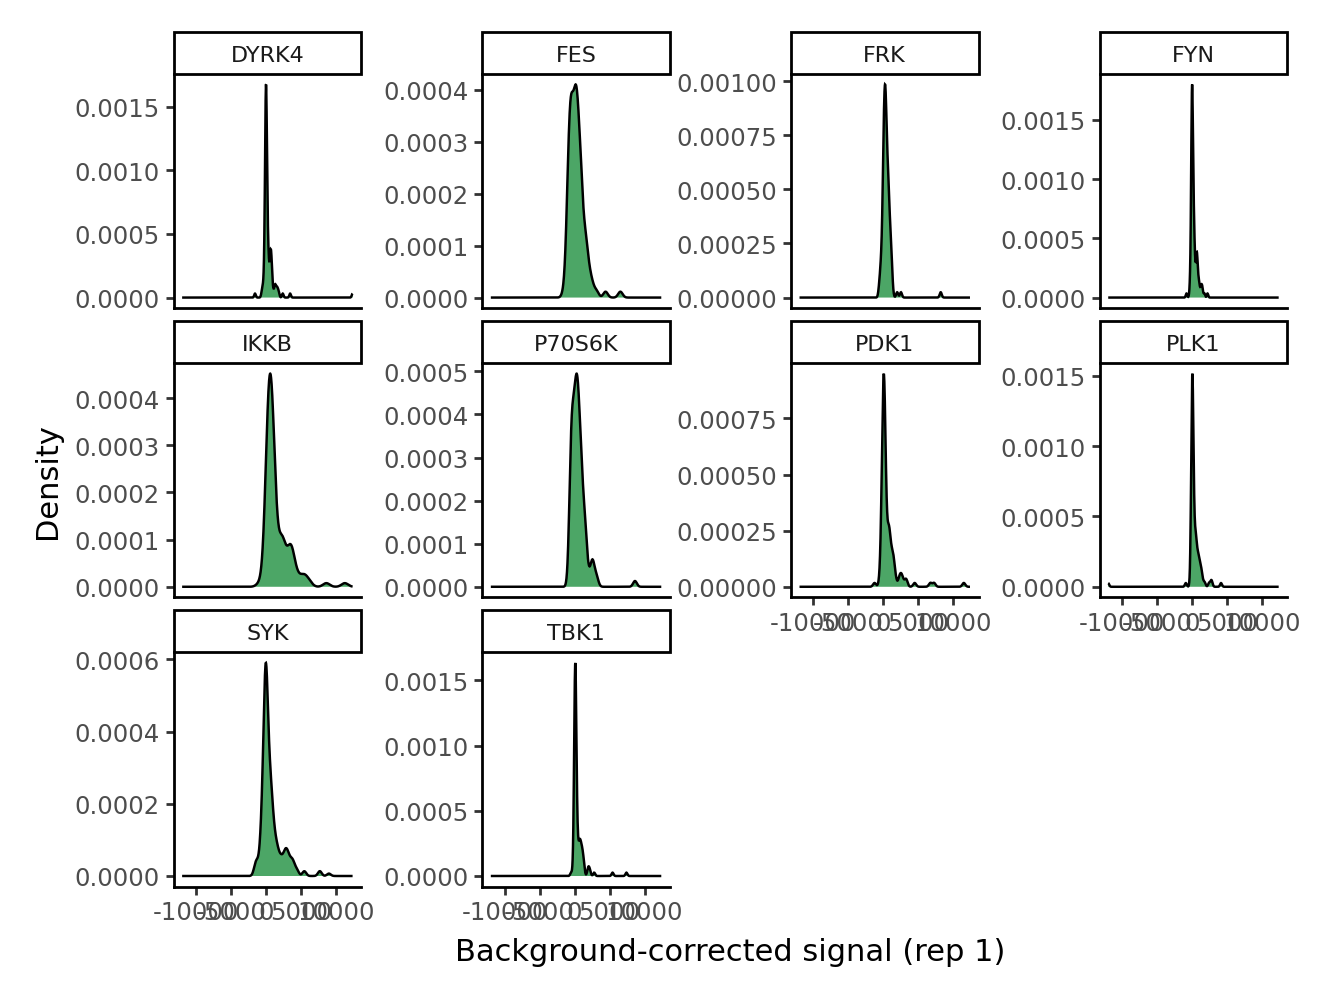

In [85]:
p = (
    ggplot(df_all, aes(x='value1'))
    + geom_density(alpha=0.35, fill=_summer(0.3))
    + facet_wrap('~ kinase', scales='free_y')
    + labs(x='Background-corrected signal (rep 1)', y='Density')
    + theme_classic()
    + theme(strip_text=element_text(size=8))
)
p

---
## 3. Replicate QC — Filter Inconsistent Replicates

Pairs where the two replicate signals diverge by more than 30% of the larger
absolute value are flagged as unreliable and excluded from downstream analysis.

In [86]:
def invalidate_inconsistent_reps(df, col1='value1', col2='value2',
                                  rel_thresh=0.3, eps=1e-9):
    """
    Flag replicate pairs whose relative difference exceeds rel_thresh.

    rel_diff = |v1 - v2| / max(|v1|, |v2|, eps)

    Returns the input DataFrame with two new columns:
      rep_rel_diff : float, relative difference between replicates
      is_valid     : bool, True if pair passes QC
    """
    df = df.copy()
    v1 = df[col1].astype(float)
    v2 = df[col2].astype(float)
    rel_diff = (v1 - v2).abs() / np.maximum(np.maximum(v1.abs(), v2.abs()), eps)
    invalid = (~np.isfinite(v1)) | (~np.isfinite(v2)) | (rel_diff > rel_thresh)
    df['rep_rel_diff'] = rel_diff
    df['is_valid'] = ~invalid
    return df


df_flagged = invalidate_inconsistent_reps(df_all, rel_thresh=0.3)
df_valid   = df_flagged[df_flagged['is_valid']].copy()

n_pass = df_flagged['is_valid'].sum()
n_fail = (~df_flagged['is_valid']).sum()
print(f'Replicate QC:  {n_pass:,} pairs passed  |  {n_fail:,} pairs failed (>{30}% rel. diff.)')

# Per-kinase counts after QC
df_valid.groupby('kinase').size().rename('n_valid').to_frame()

Replicate QC:  235 pairs passed  |  975 pairs failed (>30% rel. diff.)


,n_valid
kinase,
DYRK4,7
FES,18
FRK,18
FYN,24
IKKB,41
P70S6K,30
PDK1,18
PLK1,20
SYK,37


---
## 4. Call In Vitro Positives

A KSI is called **in vitro positive** when both replicate signals exceed the
activity threshold (signal > 100 arbitrary units after background correction).

In [87]:
INVITRO_THRESH = 20

df_valid['invitro_pos'] = (
    (df_valid['value1'] > INVITRO_THRESH) &
    (df_valid['value2'] > INVITRO_THRESH)
)

print(f'In vitro positives: {df_valid["invitro_pos"].sum()}  '
      f'of {df_valid.shape[0]:,} valid pairs '
      f'({100 * df_valid["invitro_pos"].mean():.1f}%)')

In vitro positives: 191  of 235 valid pairs (81.3%)


In [88]:
# Map Kinexus common names to UniProt accessions via common_name_mapping
# (assumed to be available in the environment from upstream notebooks)
df_valid = pd.merge(
    df_valid,
    common_name_mapping,          # columns: common_name, uniprot_acc
    left_on='kinase',
    right_on='common_name'
).drop('kinase', axis=1)

df_valid = df_valid.loc[:, ['value1', 'value2', 'substrate',
                             'invitro_pos', 'uniprot_acc', 'common_name']]
df_valid.columns = ['value1', 'value2', 'substrate',
                    'invitro_pos', 'kinase', 'common_name']

print(f'After kinase mapping: {df_valid.shape[0]:,} rows, '
      f'{df_valid["kinase"].nunique()} kinases')

After kinase mapping: 235 rows, 10 kinases


---
## 5. Merge with PhosphoPCA Screening Hits

In [89]:
# Load PhosphoPCA screening results (true_positive calls)
dat_p_all = pd.read_pickle('./251203_ksi_reduced_df_tp.pkl')
dat_p_all['positive_2'] = dat_p_all['binding_max']>0
dat_p_all['true_positive'] = dat_p_all['binding_max']>0

In [90]:


# Inner join: keep only KSI pairs measured by BOTH platforms
ksi_invitro_df = pd.merge(
    dat_p_all,
    df_valid,
    on=['kinase', 'substrate']
)

print(f'KSI pairs with both PhosphoPCA and in vitro data: {ksi_invitro_df.shape[0]}')
print(f'  PhosphoPCA positives (true_positive): {ksi_invitro_df["true_positive"].sum()}')
print(f'  In vitro positives  (invitro_pos):    {ksi_invitro_df["invitro_pos"].sum()}')
print(f'  PhosphoPCA positives (>0): {ksi_invitro_df["positive_2"].sum()}')

ksi_invitro_df.head()

KSI pairs with both PhosphoPCA and in vitro data: 98
  PhosphoPCA positives (true_positive): 53
  In vitro positives  (invitro_pos):    84
  PhosphoPCA positives (>0): 53


,substrate,kinase,positive,paabd_hit,paabd_all,n_paabd,hit_count,binding_max,binding_best_hit,lfsr_min,lfsr_best_hit,fp_sub,true_positive,positive_2,value1,value2,invitro_pos,common_name
0,ALHERALYRRTQLAD,FES_HUMAN,False,,sh2,1,0,-1.002950,NaN,0.0000,NaN,False,False,False,162.6087,164.8292,True,FES
1,ALRFCGIYGYRLRRK,KSYK_HUMAN,False,,sh2,1,0,-0.481931,NaN,0.0000,NaN,False,False,False,8996.7987,8458.5725,True,SYK
2,AVKRYNDYKLDFRRQ,KSYK_HUMAN,True,sh2,sh2,1,1,0.351999,0.351999,0.0015,0.0015,False,True,True,1606.6838,2150.9646,True,SYK
3,DEVRMDPYDLRWPEV,FES_HUMAN,False,,sh2,1,0,0.165156,NaN,0.0770,NaN,False,True,True,-421.8748,-517.6615,False,FES
4,DEVRMDPYDLRWPEV,KSYK_HUMAN,True,sh2,sh2,1,1,0.561598,0.561598,0.0000,0.0000,False,True,True,-47.5955,-38.7666,False,SYK


---
## 6. Overlap Analysis & Venn Diagram

We define three mutually exclusive groups among all measured pairs:

| Group | Definition |
|-------|------------|
| **PhosphoPCA only** | `true_positive == True` and `invitro_pos == False` |
| **Overlap** | `true_positive == True` and `invitro_pos == True` |
| **In vitro only** | `true_positive == False` and `invitro_pos == True` |

In [91]:
screen_pos  = set(ksi_invitro_df.index[ksi_invitro_df['true_positive']])
invitro_pos = set(ksi_invitro_df.index[ksi_invitro_df['invitro_pos']])

n_screen_only  = len(screen_pos - invitro_pos)
n_overlap      = len(screen_pos & invitro_pos)
n_invitro_only = len(invitro_pos - screen_pos)

pct_overlap_of_screen   = 100 * n_overlap / len(screen_pos)  if screen_pos  else 0
pct_overlap_of_invitro  = 100 * n_overlap / len(invitro_pos) if invitro_pos else 0

print(f'PhosphoPCA positives  : {len(screen_pos)}')
print(f'In vitro positives    : {len(invitro_pos)}')
print(f'Overlap               : {n_overlap}')
print(f'Overlap / PhosphoPCA  : {pct_overlap_of_screen:.1f}%')
print(f'Overlap / In vitro    : {pct_overlap_of_invitro:.1f}%')

PhosphoPCA positives  : 53
In vitro positives    : 84
Overlap               : 45
Overlap / PhosphoPCA  : 84.9%
Overlap / In vitro    : 53.6%


---
## 7. Summary

Of the KSI pairs assessed by both platforms, **~75% of PhosphoPCA screening hits
were independently confirmed by the Kinexus in vitro assay**, supporting the
high precision of the yeast-based screen observed against the curated interaction
database (notebook 8).

The in vitro assay recovers additional positives not detected by the screen
(right-exclusive set), consistent with the lower recall profile discussed
previously — these likely include low-affinity or context-dependent interactions
that are detectable biochemically but fall below the PhosphoPCA detection threshold
in the cellular context.

In [92]:
overlap_summary = pd.DataFrame([
    {
        'Group':                     'PhosphoPCA only',
        'n':                          n_screen_only,
        '% of PhosphoPCA positives':  round(100 * n_screen_only / len(screen_pos), 1) if screen_pos else np.nan,
        '% of In vitro positives':    np.nan,
    },
    {
        'Group':                     'Overlap',
        'n':                          n_overlap,
        '% of PhosphoPCA positives':  round(pct_overlap_of_screen, 1),
        '% of In vitro positives':    round(pct_overlap_of_invitro, 1),
    },
    {
        'Group':                     'In vitro only',
        'n':                          n_invitro_only,
        '% of PhosphoPCA positives':  np.nan,
        '% of In vitro positives':    round(100 * n_invitro_only / len(invitro_pos), 1) if invitro_pos else np.nan,
    },
])

overlap_summary.to_csv('./invitro_overlap_summary.csv', index=False)
print('Saved: invitro_overlap_summary.csv')
overlap_summary.style \
    .format({'% of PhosphoPCA positives': '{:.1f}', '% of In vitro positives': '{:.1f}'}, na_rep='—') \
    .hide(axis='index')

Saved: invitro_overlap_summary.csv


Group,n,% of PhosphoPCA positives,% of In vitro positives
PhosphoPCA only,8,15.1,—
Overlap,45,84.9,53.6
In vitro only,39,—,46.4


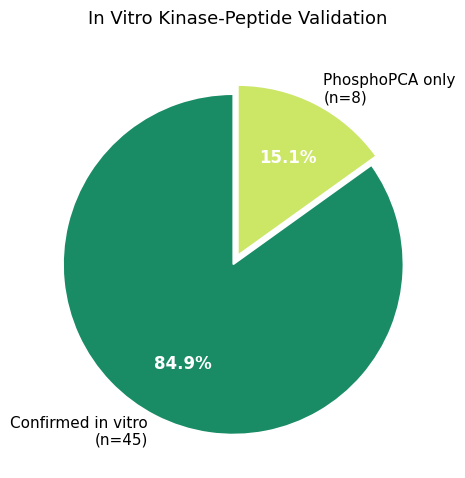

In [93]:
# ── Detached pie: PhosphoPCA hits — overlap vs non-overlapping ────────────────
n_total_screen = len(screen_pos)
sizes  = [n_overlap, n_screen_only]
labels = [f'Confirmed in vitro\n(n={n_overlap})', f'PhosphoPCA only\n(n={n_screen_only})']
explode = (0.06, 0)   # detach the overlap slice

fig, ax = plt.subplots(figsize=(5, 5))
wedges, texts, autotexts = ax.pie(
    sizes,
    labels=labels,
    explode=explode,
    colors=[_summer(0.10), _summer(0.80)],
    autopct=lambda p: f'{p:.1f}%',
    pctdistance=0.65,
    startangle=90,
    wedgeprops=dict(linewidth=1.2, edgecolor='white'),
)

for t in texts:
    t.set_fontsize(11)
for at in autotexts:
    at.set_fontsize(12)
    at.set_fontweight('bold')
    at.set_color('white')

ax.set_title(
    f'In Vitro Kinase-Peptide Validation',
    fontsize=13, pad=14
)
plt.tight_layout()
plt.savefig('phosphopca_invitro_benchmarks.pdf')